# 01 — Data Exploration & Visual Validation

This notebook validates the ingested data visually and begins research for Module 2.

**Sections:**
1. Data Inventory
2. Price Charts
3. Return Distributions
4. Volatility Over Time
5. Correlation Matrix
6. Funding Rate Analysis
7. Sentiment Overlay

In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['figure.dpi'] = 100

# Connect to research DB
db_path = Path('../data/research.duckdb')
con = duckdb.connect(str(db_path), read_only=True)
print('Connected to research DB')

Matplotlib is building the font cache; this may take a moment.


Connected to research DB


## 1. Data Inventory
How many rows per pair, per timeframe? Any surprises?

In [2]:
# Row counts per symbol/timeframe
inventory = con.execute("""
    SELECT symbol, timeframe, 
           COUNT(*) as rows,
           MIN(timestamp) as start_date,
           MAX(timestamp) as end_date,
           ROUND(COUNT(*) * 100.0 / (
               CASE timeframe
                   WHEN '1m' THEN DATEDIFF('minute', MIN(timestamp), MAX(timestamp))
                   WHEN '5m' THEN DATEDIFF('minute', MIN(timestamp), MAX(timestamp)) / 5
                   WHEN '1h' THEN DATEDIFF('hour', MIN(timestamp), MAX(timestamp))
                   WHEN '4h' THEN DATEDIFF('hour', MIN(timestamp), MAX(timestamp)) / 4
                   WHEN '1d' THEN DATEDIFF('day', MIN(timestamp), MAX(timestamp))
               END
           ), 2) as completeness_pct
    FROM ohlcv
    GROUP BY symbol, timeframe
    ORDER BY symbol, timeframe
""").fetchdf()

print(f"Total OHLCV rows: {inventory['rows'].sum():,}")
print(f"\nFunding rates: {con.execute('SELECT COUNT(*) FROM funding_rates').fetchone()[0]:,} rows")
print(f"Sentiment:     {con.execute('SELECT COUNT(*) FROM sentiment').fetchone()[0]:,} rows")
print()
inventory

Total OHLCV rows: 12,554,179

Funding rates: 7,138 rows
Sentiment:     2,981 rows



,symbol,timeframe,rows,start_date,end_date,completeness_pct
0,BNB/USDT,1d,1190,2023-01-01 01:00:00+01:00,2026-04-04 01:00:00+01:00,100.08
1,BNB/USDT,1h,28550,2023-01-01 01:00:00+01:00,2026-04-04 14:00:00+01:00,100.00
2,BNB/USDT,1m,1712918,2023-01-01 01:00:00+01:00,2026-04-04 14:57:00+01:00,100.00
3,BNB/USDT,4h,7138,2023-01-01 01:00:00+01:00,2026-04-04 13:00:00+01:00,100.01
4,BNB/USDT,5m,342580,2023-01-01 01:00:00+01:00,2026-04-04 14:35:00+01:00,100.00
5,BTC/USDT,1d,1190,2023-01-01 01:00:00+01:00,2026-04-04 01:00:00+01:00,100.08
6,BTC/USDT,1h,28549,2023-01-01 01:00:00+01:00,2026-04-04 13:00:00+01:00,100.00
7,BTC/USDT,1m,1712854,2023-01-01 01:00:00+01:00,2026-04-04 13:53:00+01:00,100.00
8,BTC/USDT,4h,7138,2023-01-01 01:00:00+01:00,2026-04-04 13:00:00+01:00,100.01
9,BTC/USDT,5m,342568,2023-01-01 01:00:00+01:00,2026-04-04 13:35:00+01:00,100.00


## 2. Price Charts
Visual sanity check — do the prices look right?

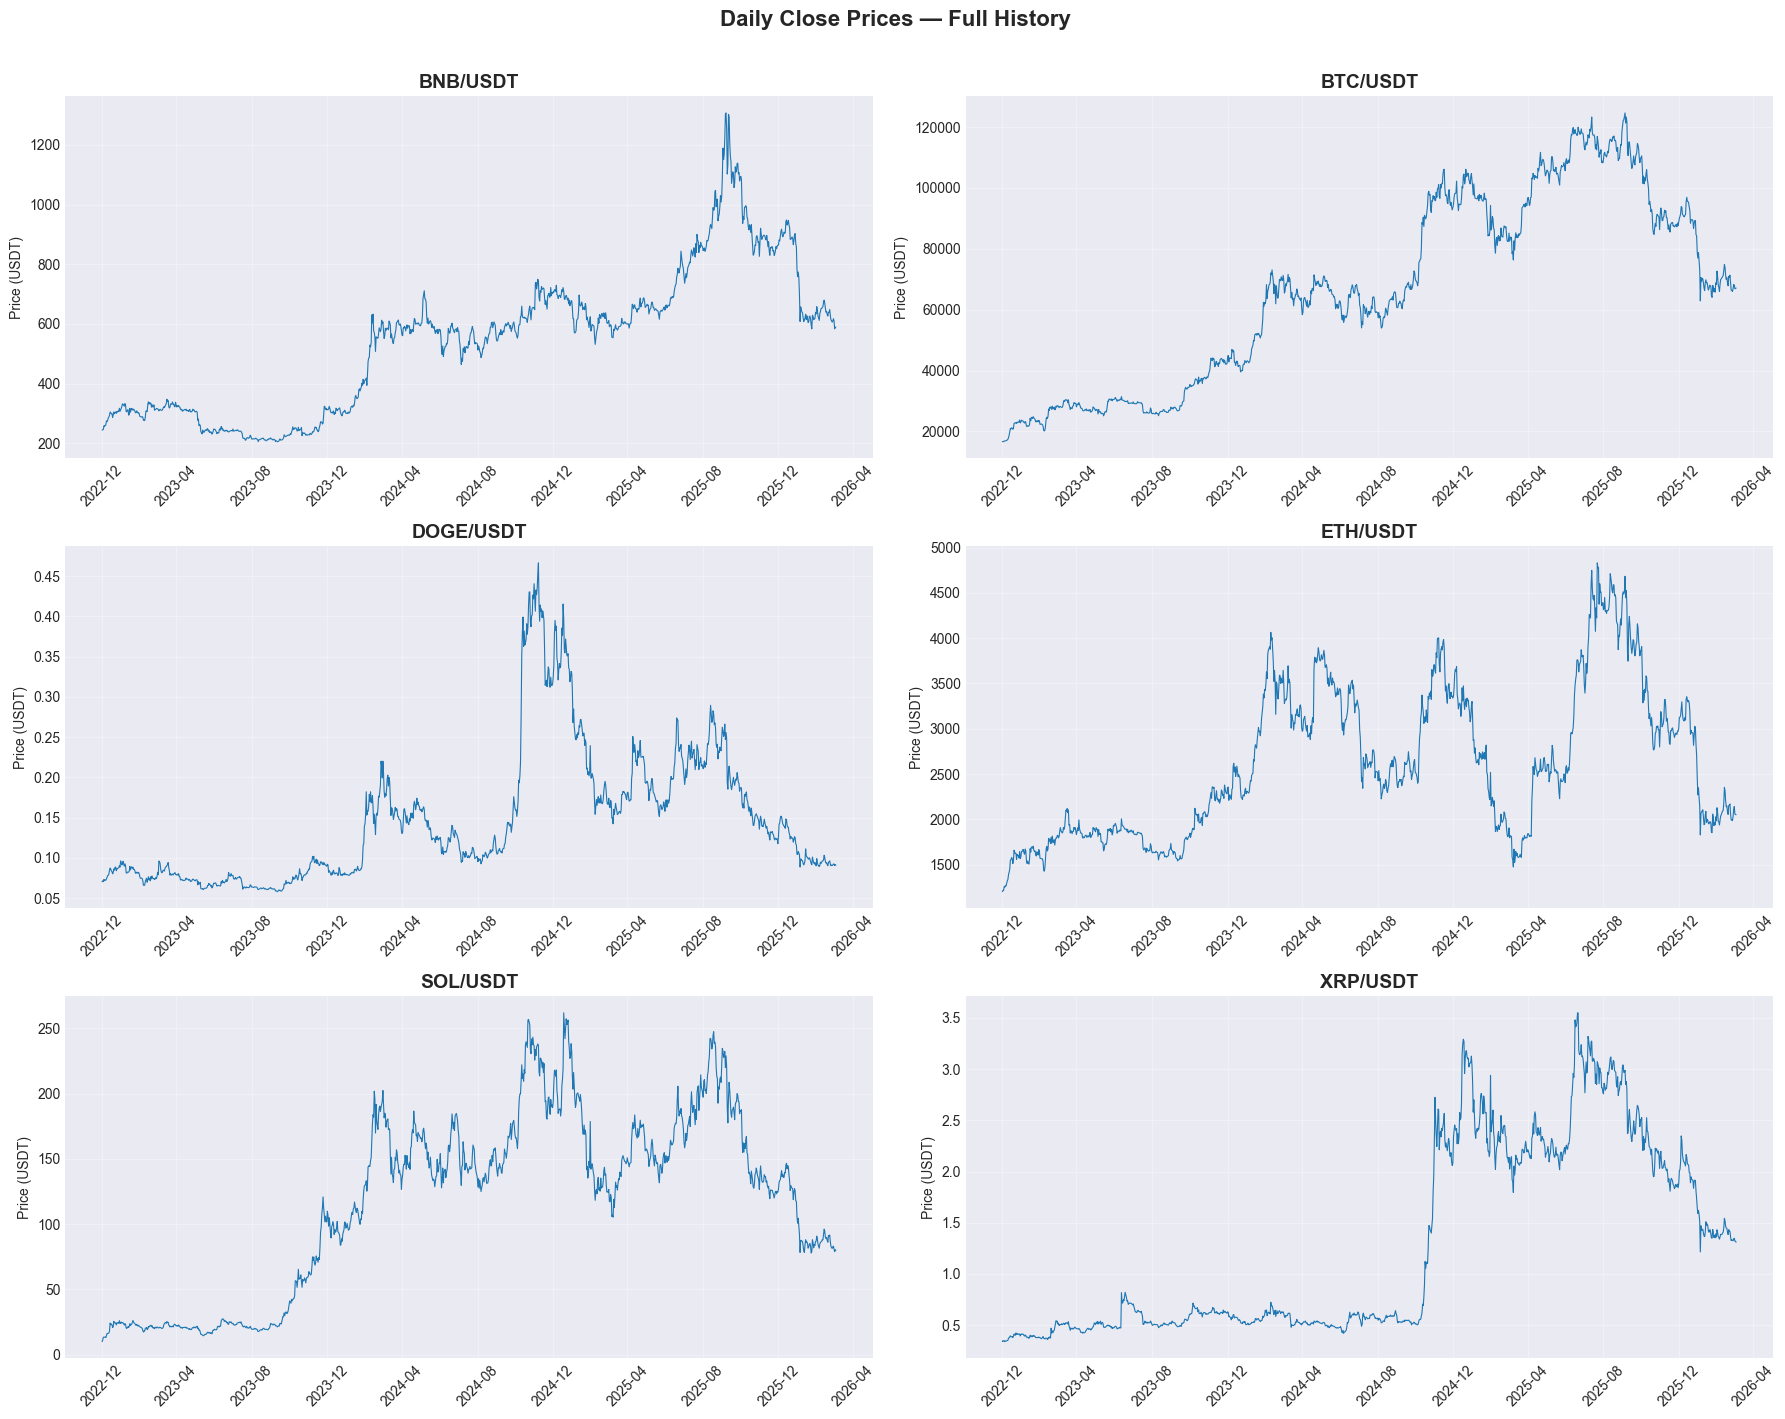

In [3]:
# Fetch daily close prices for all pairs
daily = con.execute("""
    SELECT timestamp, symbol, close
    FROM ohlcv
    WHERE timeframe = '1d'
    ORDER BY symbol, timestamp
""").fetchdf()

symbols = daily['symbol'].unique()
fig, axes = plt.subplots(3, 2, figsize=(18, 14))
axes = axes.flatten()

for i, symbol in enumerate(sorted(symbols)):
    ax = axes[i]
    df = daily[daily['symbol'] == symbol]
    ax.plot(df['timestamp'], df['close'], linewidth=0.8)
    ax.set_title(symbol, fontsize=14, fontweight='bold')
    ax.set_ylabel('Price (USDT)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)

plt.suptitle('Daily Close Prices — Full History', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 3. Return Distributions
Histogram of hourly returns. Expect fat tails — crypto is NOT normally distributed.

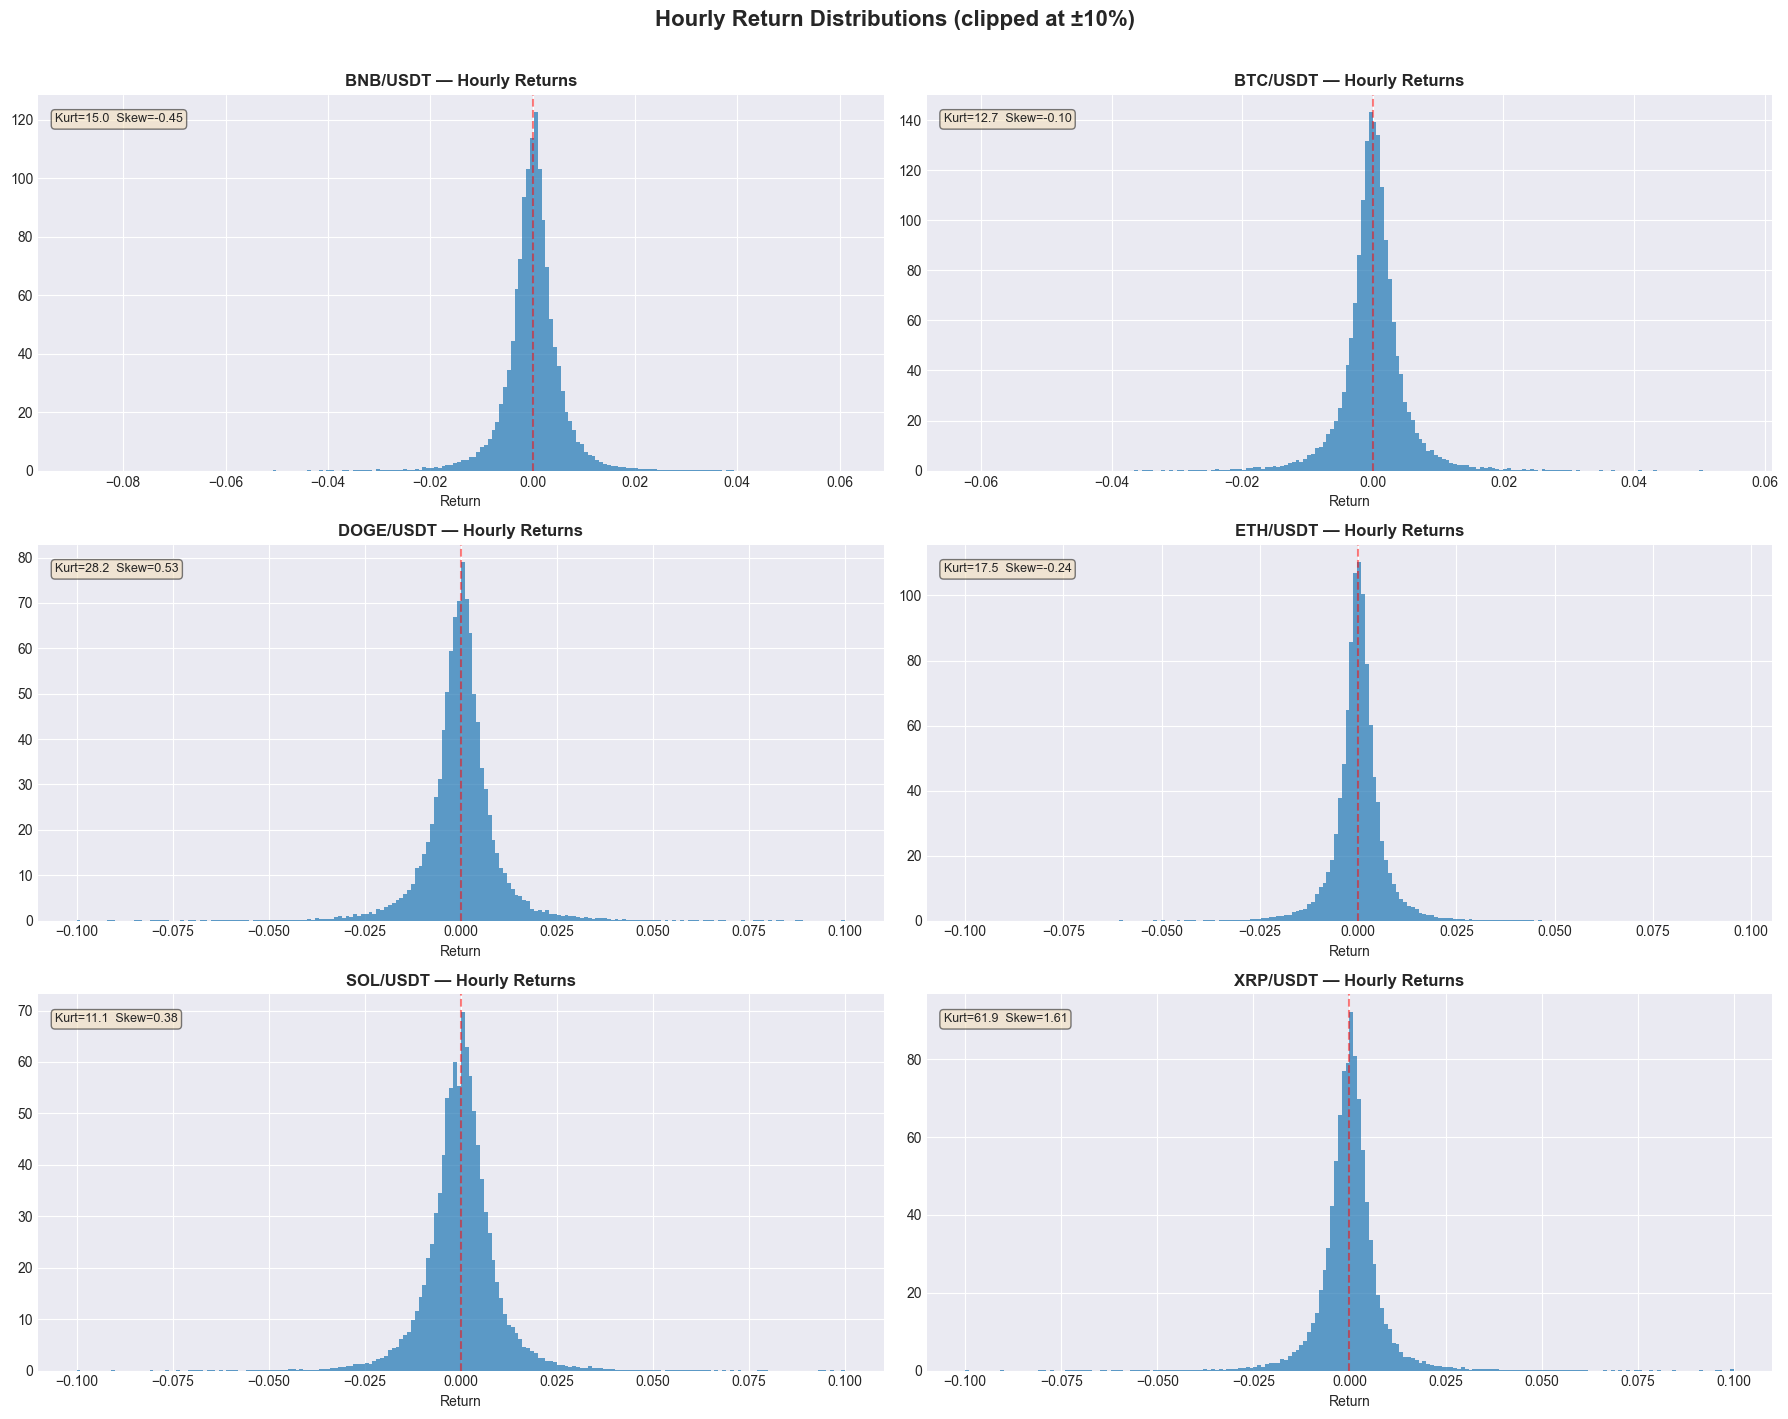


Return Statistics:


,mean_return,std,skewness,kurtosis,min,max
symbol,,,,,,
BNB/USDT,0.000048,0.0059,-0.45,15.0,-0.0891,0.0611
BTC/USDT,0.000062,0.0050,-0.10,12.7,-0.0624,0.0553
DOGE/USDT,0.000058,0.0098,0.53,28.2,-0.1502,0.2261
ETH/USDT,0.000041,0.0067,-0.24,17.5,-0.1174,0.0956
SOL/USDT,0.000119,0.0096,0.38,11.1,-0.1056,0.1284
XRP/USDT,0.000086,0.0088,1.61,61.9,-0.1489,0.2471


In [4]:
# Fetch hourly closes and compute returns
hourly = con.execute("""
    SELECT timestamp, symbol, close
    FROM ohlcv
    WHERE timeframe = '1h'
    ORDER BY symbol, timestamp
""").fetchdf()

fig, axes = plt.subplots(3, 2, figsize=(18, 14))
axes = axes.flatten()

stats_rows = []

for i, symbol in enumerate(sorted(symbols)):
    ax = axes[i]
    df = hourly[hourly['symbol'] == symbol].copy()
    df['return'] = df['close'].pct_change()
    returns = df['return'].dropna()
    
    # Clip for visualization (keep actual stats)
    ax.hist(returns.clip(-0.1, 0.1), bins=200, alpha=0.7, density=True, edgecolor='none')
    ax.set_title(f'{symbol} — Hourly Returns', fontsize=12, fontweight='bold')
    ax.set_xlabel('Return')
    ax.axvline(0, color='red', linestyle='--', alpha=0.5)
    
    # Stats
    kurt = returns.kurtosis()
    skew = returns.skew()
    stats_rows.append({
        'symbol': symbol,
        'mean_return': f"{returns.mean():.6f}",
        'std': f"{returns.std():.4f}",
        'skewness': f"{skew:.2f}",
        'kurtosis': f"{kurt:.1f}",
        'min': f"{returns.min():.4f}",
        'max': f"{returns.max():.4f}",
    })
    ax.text(0.02, 0.95, f'Kurt={kurt:.1f}  Skew={skew:.2f}',
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('Hourly Return Distributions (clipped at ±10%)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('\nReturn Statistics:')
pd.DataFrame(stats_rows).set_index('symbol')

## 4. Volatility Over Time
Rolling 30-day annualized volatility. Can you see regime changes?

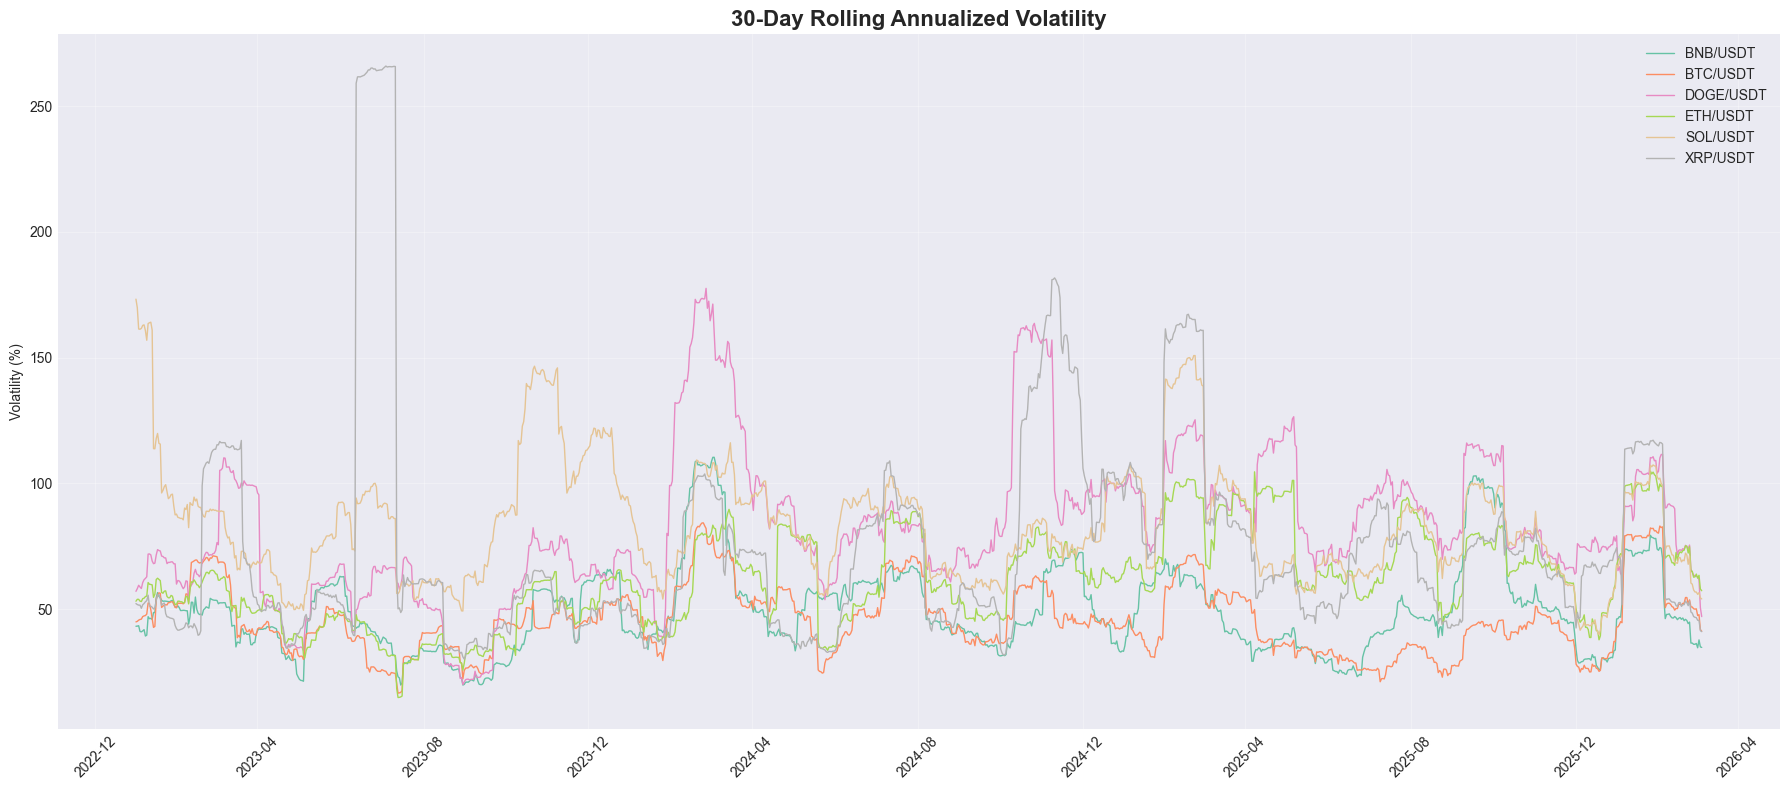

In [5]:
fig, ax = plt.subplots(figsize=(18, 8))

colors = plt.cm.Set2(np.linspace(0, 1, len(symbols)))

for i, symbol in enumerate(sorted(symbols)):
    df = daily[daily['symbol'] == symbol].copy()
    df = df.set_index('timestamp').sort_index()
    df['return'] = df['close'].pct_change()
    # 30-day rolling volatility, annualized
    df['vol_30d'] = df['return'].rolling(30).std() * np.sqrt(365) * 100
    ax.plot(df.index, df['vol_30d'], label=symbol, linewidth=1, color=colors[i])

ax.set_title('30-Day Rolling Annualized Volatility', fontsize=16, fontweight='bold')
ax.set_ylabel('Volatility (%)')
ax.legend(loc='upper right', fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# INSIGHT: Look for periods where volatility spikes (regime transitions)
# and periods where it clusters at different levels (distinct regimes)

## 5. Correlation Matrix
How do the 6 pairs correlate? Does it change over time?

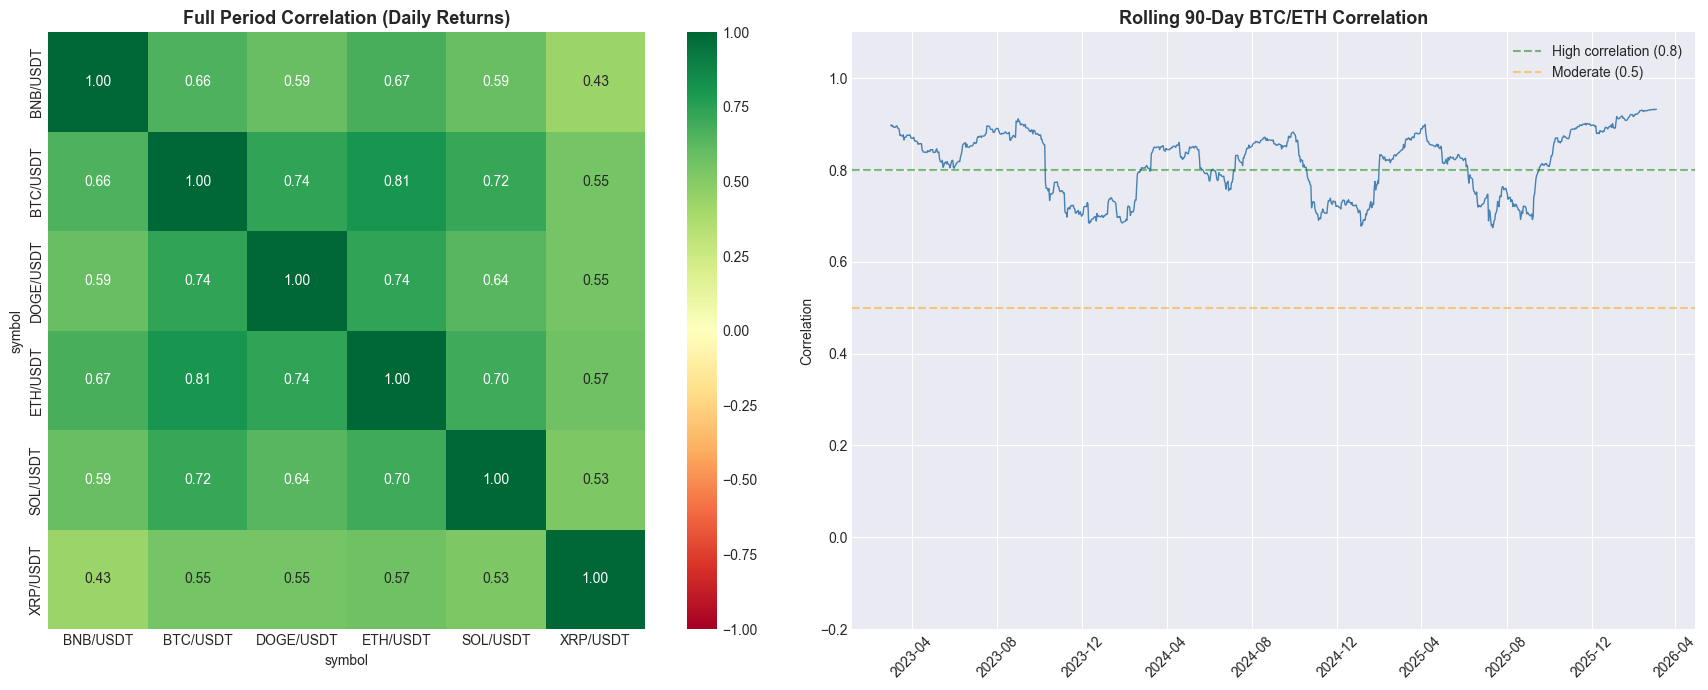


BTC/ETH correlation range: 0.67 to 0.93
BTC/ETH mean correlation: 0.82


In [6]:
# Pivot daily returns into wide format
daily_pivot = daily.pivot_table(index='timestamp', columns='symbol', values='close')
daily_returns = daily_pivot.pct_change().dropna()

# Full-period correlation
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left: full period correlation
corr_full = daily_returns.corr()
sns.heatmap(corr_full, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title('Full Period Correlation (Daily Returns)', fontsize=13, fontweight='bold')

# Right: rolling 90-day BTC/ETH correlation
rolling_corr = daily_returns['BTC/USDT'].rolling(90).corr(daily_returns['ETH/USDT'])
axes[1].plot(rolling_corr.index, rolling_corr, color='steelblue', linewidth=1)
axes[1].axhline(0.8, color='green', linestyle='--', alpha=0.5, label='High correlation (0.8)')
axes[1].axhline(0.5, color='orange', linestyle='--', alpha=0.5, label='Moderate (0.5)')
axes[1].set_title('Rolling 90-Day BTC/ETH Correlation', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Correlation')
axes[1].legend()
axes[1].set_ylim(-0.2, 1.1)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f'\nBTC/ETH correlation range: {rolling_corr.min():.2f} to {rolling_corr.max():.2f}')
print(f'BTC/ETH mean correlation: {rolling_corr.mean():.2f}')

## 6. Funding Rate Analysis
Positive funding = longs paying shorts (bullish positioning).
Negative funding = shorts paying longs (bearish positioning).

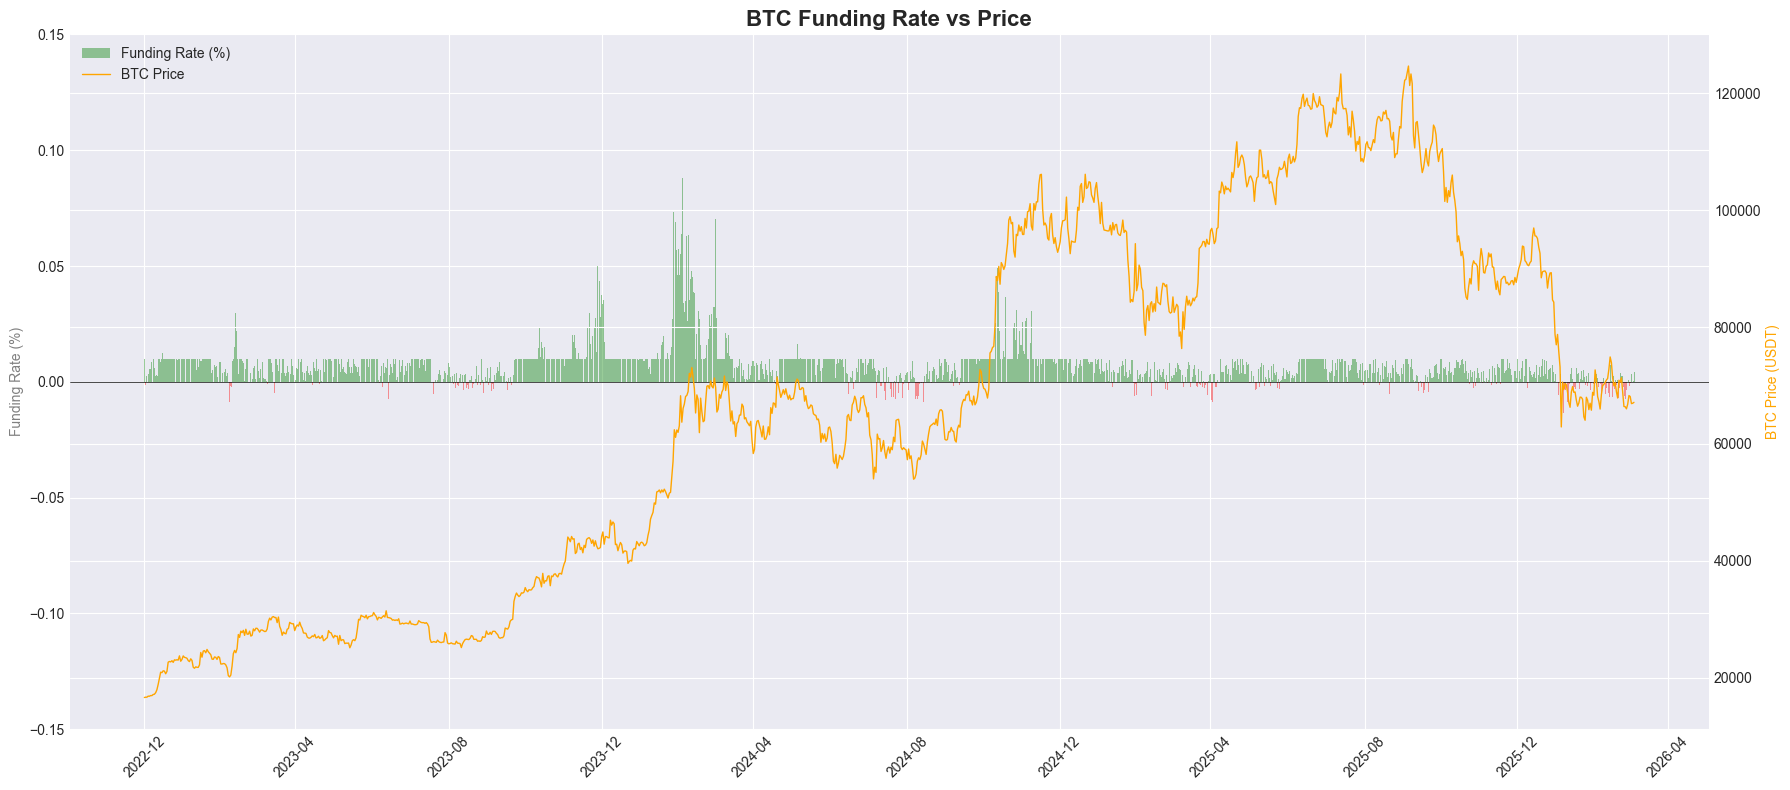

BTC Funding Rate Stats:
  Mean: 0.0071%
  Positive (bullish): 3119 / 3569 (87.4%)
  Negative (bearish): 450 / 3569 (12.6%)


In [7]:
# Fetch funding rates
funding = con.execute("""
    SELECT timestamp, symbol, funding_rate
    FROM funding_rates
    ORDER BY symbol, timestamp
""").fetchdf()

# BTC funding rate + price overlay
btc_funding = funding[funding['symbol'] == 'BTC/USDT:USDT'].set_index('timestamp').sort_index()
btc_daily = daily[daily['symbol'] == 'BTC/USDT'].set_index('timestamp').sort_index()

fig, ax1 = plt.subplots(figsize=(18, 8))

# Funding rate as bar chart
colors_funding = ['green' if x >= 0 else 'red' for x in btc_funding['funding_rate']]
ax1.bar(btc_funding.index, btc_funding['funding_rate'] * 100, 
        color=colors_funding, alpha=0.4, width=0.3, label='Funding Rate (%)')
ax1.set_ylabel('Funding Rate (%)', color='gray')
ax1.axhline(0, color='black', linestyle='-', linewidth=0.5)
ax1.set_ylim(-0.15, 0.15)

# BTC price on secondary axis
ax2 = ax1.twinx()
ax2.plot(btc_daily.index, btc_daily['close'], color='orange', linewidth=1, label='BTC Price')
ax2.set_ylabel('BTC Price (USDT)', color='orange')

ax1.set_title('BTC Funding Rate vs Price', fontsize=16, fontweight='bold')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax1.tick_params(axis='x', rotation=45)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

# Funding rate stats
print('BTC Funding Rate Stats:')
print(f"  Mean: {btc_funding['funding_rate'].mean()*100:.4f}%")
print(f"  Positive (bullish): {(btc_funding['funding_rate'] > 0).sum()} / {len(btc_funding)} ({(btc_funding['funding_rate'] > 0).mean()*100:.1f}%)")
print(f"  Negative (bearish): {(btc_funding['funding_rate'] < 0).sum()} / {len(btc_funding)} ({(btc_funding['funding_rate'] < 0).mean()*100:.1f}%)")

## 7. Sentiment Overlay
Fear & Greed Index alongside BTC price. Do extremes predict reversals?

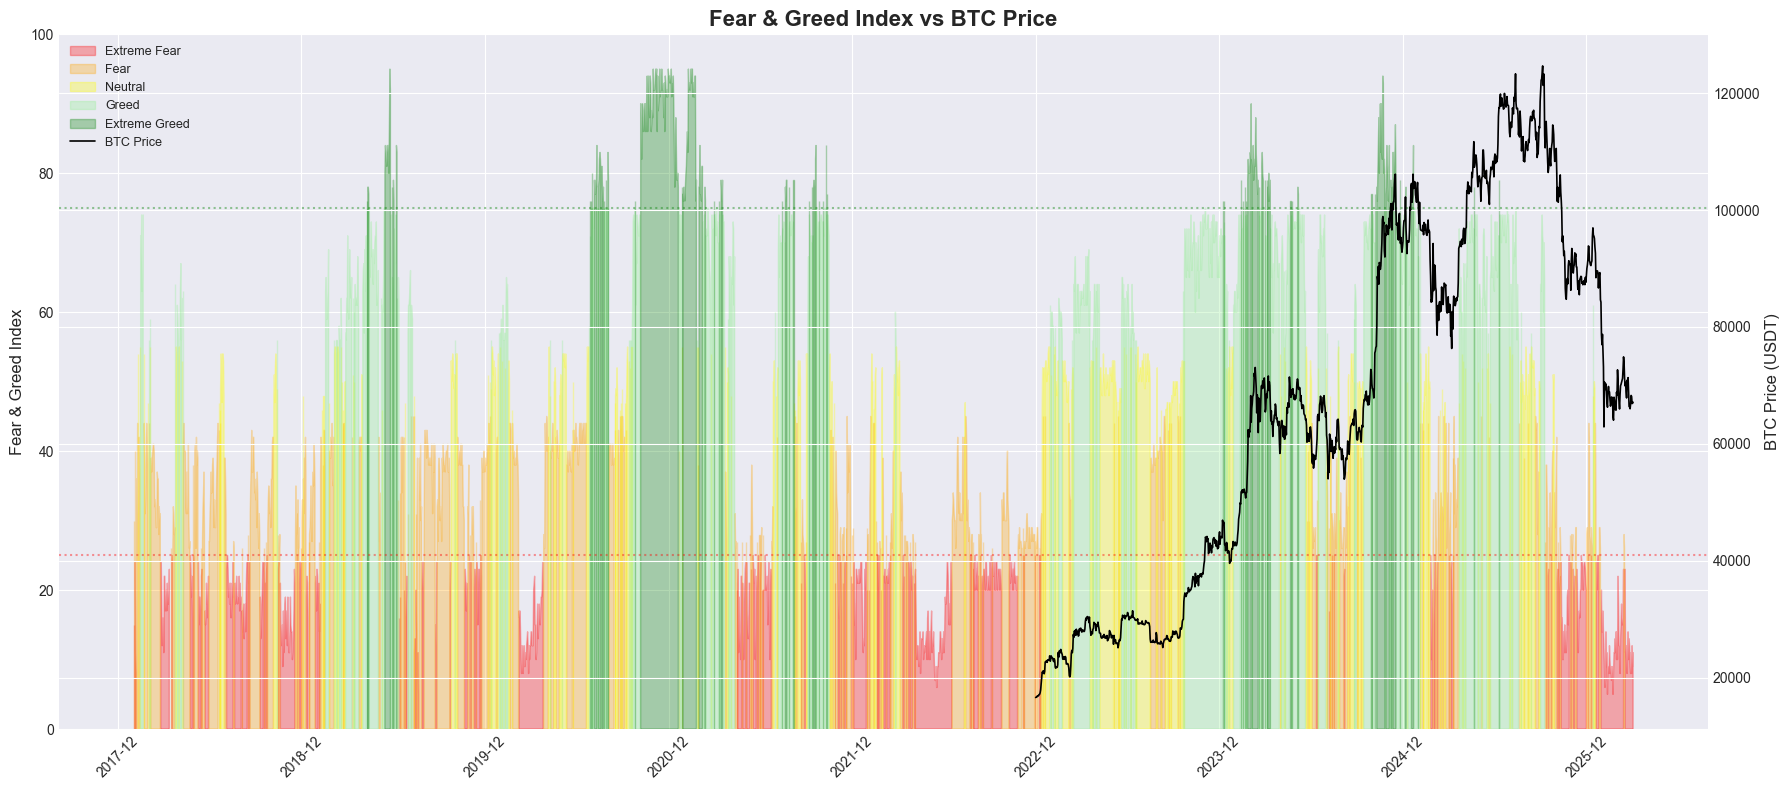

In [8]:
# Fetch sentiment data
sentiment = con.execute("""
    SELECT timestamp, value, classification
    FROM sentiment
    ORDER BY timestamp
""").fetchdf()
sentiment = sentiment.set_index('timestamp').sort_index()

# Align with BTC price (only overlapping dates)
btc_price = btc_daily['close']

fig, ax1 = plt.subplots(figsize=(18, 8))

# Sentiment as colored background
ax1.fill_between(sentiment.index, 0, sentiment['value'],
                 where=(sentiment['value'] <= 25), color='red', alpha=0.3, label='Extreme Fear')
ax1.fill_between(sentiment.index, 0, sentiment['value'],
                 where=((sentiment['value'] > 25) & (sentiment['value'] <= 45)), color='orange', alpha=0.3, label='Fear')
ax1.fill_between(sentiment.index, 0, sentiment['value'],
                 where=((sentiment['value'] > 45) & (sentiment['value'] <= 55)), color='yellow', alpha=0.3, label='Neutral')
ax1.fill_between(sentiment.index, 0, sentiment['value'],
                 where=((sentiment['value'] > 55) & (sentiment['value'] <= 75)), color='lightgreen', alpha=0.3, label='Greed')
ax1.fill_between(sentiment.index, 0, sentiment['value'],
                 where=(sentiment['value'] > 75), color='green', alpha=0.3, label='Extreme Greed')

ax1.set_ylabel('Fear & Greed Index', fontsize=12)
ax1.set_ylim(0, 100)
ax1.axhline(25, color='red', linestyle=':', alpha=0.4)
ax1.axhline(75, color='green', linestyle=':', alpha=0.4)

# BTC price overlay
ax2 = ax1.twinx()
ax2.plot(btc_price.index, btc_price, color='black', linewidth=1.2, label='BTC Price')
ax2.set_ylabel('BTC Price (USDT)', fontsize=12)

ax1.set_title('Fear & Greed Index vs BTC Price', fontsize=16, fontweight='bold')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax1.tick_params(axis='x', rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

## Key Insights

Document at least 3 observations from the data:

In [9]:
# Compute key metrics for insight documentation

# 1. Correlation breakdown during specific periods
btc_eth_corr = daily_returns['BTC/USDT'].rolling(90).corr(daily_returns['ETH/USDT'])
corr_min_date = btc_eth_corr.idxmin()
corr_min_val = btc_eth_corr.min()

# 2. Volatility regimes
btc_vol = daily[daily['symbol'] == 'BTC/USDT'].set_index('timestamp')['close'].pct_change().rolling(30).std() * np.sqrt(365) * 100
high_vol_periods = (btc_vol > 80).sum()
low_vol_periods = (btc_vol < 30).sum()

# 3. Sentiment extremes
extreme_fear_days = (sentiment['value'] <= 20).sum()
extreme_greed_days = (sentiment['value'] >= 80).sum()

# 4. Kurtosis (fat tails)
btc_hourly = hourly[hourly['symbol'] == 'BTC/USDT']['close'].pct_change().dropna()
btc_kurt = btc_hourly.kurtosis()

print('=' * 60)
print('KEY INSIGHTS FROM DATA EXPLORATION')
print('=' * 60)
print()
print(f'INSIGHT 1 — Correlation Breakdown')
print(f'  BTC/ETH 90-day rolling correlation dropped to {corr_min_val:.2f} around {corr_min_date}')
print(f'  This suggests diversification opportunities exist during certain regimes.')
print()
print(f'INSIGHT 2 — Volatility Regimes Are Clearly Visible')
print(f'  {high_vol_periods} days with >80% annualized vol (crisis/mania)')
print(f'  {low_vol_periods} days with <30% annualized vol (compression)')
print(f'  Regime detection (Module 4) should capture these transitions.')
print()
print(f'INSIGHT 3 — Fat Tails Confirmed')
print(f'  BTC hourly return kurtosis: {btc_kurt:.1f} (normal distribution = 3.0)')
print(f'  This means extreme moves happen FAR more often than a normal model predicts.')
print(f'  Risk management MUST account for this — no Gaussian assumptions.')
print()
print(f'INSIGHT 4 — Sentiment Extremes')
print(f'  {extreme_fear_days} days of extreme fear (<=20), {extreme_greed_days} days of extreme greed (>=80)')
print(f'  These may serve as contrarian signals — worth testing in Module 2.')
print()
print('=' * 60)

KEY INSIGHTS FROM DATA EXPLORATION

INSIGHT 1 — Correlation Breakdown
  BTC/ETH 90-day rolling correlation dropped to 0.67 around 2025-08-12 01:00:00+01:00
  This suggests diversification opportunities exist during certain regimes.

INSIGHT 2 — Volatility Regimes Are Clearly Visible
  19 days with >80% annualized vol (crisis/mania)
  139 days with <30% annualized vol (compression)
  Regime detection (Module 4) should capture these transitions.

INSIGHT 3 — Fat Tails Confirmed
  BTC hourly return kurtosis: 12.7 (normal distribution = 3.0)
  This means extreme moves happen FAR more often than a normal model predicts.
  Risk management MUST account for this — no Gaussian assumptions.

INSIGHT 4 — Sentiment Extremes
  386 days of extreme fear (<=20), 165 days of extreme greed (>=80)
  These may serve as contrarian signals — worth testing in Module 2.



In [10]:
con.close()
print('Database connection closed.')

Database connection closed.
